<a href="https://colab.research.google.com/github/europecodingschool/ECS---VB---YZ---08.26/blob/main/VB_YZ_Ders_22_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import keras
from keras import layers
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [2]:
# VERİYİ YÜKLEME- HAZIR VERİ SETİNDEN FAYDALANACAĞIZ.
#https://keras.io/api/datasets/fashion_mnist/

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
print("x_train şekli:", x_train.shape)
print("y_train şekli:", y_train.shape)
print("x_test şekli:", x_test.shape)
print("y_test şekli:", y_test.shape)

x_train şekli: (60000, 28, 28)
y_train şekli: (60000,)
x_test şekli: (10000, 28, 28)
y_test şekli: (10000,)


In [4]:
# Datamızı linkten incelediğimizde sınıfların sayısal olduğunu görüyoruz. (0-9 arası)Biz bunu anlayacağımız şekle çevirelim.

sinif_adlari = ["Tişört/Üst", "Pantalon", "Kazak", "Elbise", "Mont", "Sandalet", "Gömlek", "Spor Ayakkabı", "Çanta", "Bot"]

print("İlk 10 Etiket:", y_train[:10])
print("İlk ürün:", sinif_adlari[y_train[0]])
print("İlk ürün:", sinif_adlari[y_train[1]])

İlk 10 Etiket: [9 0 0 3 0 2 7 2 5 5]
İlk ürün: Bot
İlk ürün: Tişört/Üst


In [5]:
#BİR RESİM ASLINDA NE?

print("veri tipi:", x_train.dtype)
print("En küçük piksel:", x_train.min()) # en küçük değer ve en büyük değer. teoride pixelin 0 - 255 arasında olduğunu görmüştük. İspatladık
print("En büyük piksel:", x_train.max())
print(x_train[0][10:24,4:18]) # Bir parça seçip nasıl göründüğüne baktık.


veri tipi: uint8
En küçük piksel: 0
En büyük piksel: 255
[[  0   0   0   0   0   0   0   0   0 193 228 218 213 198]
 [  0   0   0   0   0   1   3   0  12 219 220 212 218 192]
 [  0   0   0   0   0   0   6   0  99 244 222 220 218 203]
 [  0   0   0   0   0   4   0   0  55 236 228 230 228 240]
 [  6   7   2   0   0   0   0   0 237 226 217 223 222 219]
 [  0   0   0   0   0  62 145 204 228 207 213 221 218 208]
 [ 18  44  82 107 189 228 220 222 217 226 200 205 211 230]
 [224 221 224 208 204 214 208 209 200 159 245 193 206 223]
 [221 211 211 214 205 205 205 220 240  80 150 255 229 221]
 [222 229 229 234 249 220 194 215 217 241  65  73 106 117]
 [193 205 211 225 216 185 197 206 198 213 240 195 227 245]
 [213 197 185 190 194 192 202 214 219 221 220 236 225 216]
 [179 171 183 196 204 210 213 207 211 210 200 196 194 191]
 [212 191 175 172 175 181 185 188 189 188 193 198 204 209]]


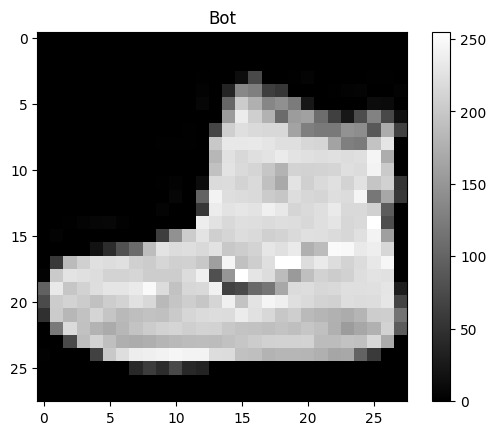

In [6]:
# RESİM ÇİZME

plt.imshow(x_train[0],cmap="gray")
plt.colorbar()
plt.title(sinif_adlari[y_train[0]])
plt.show()
#

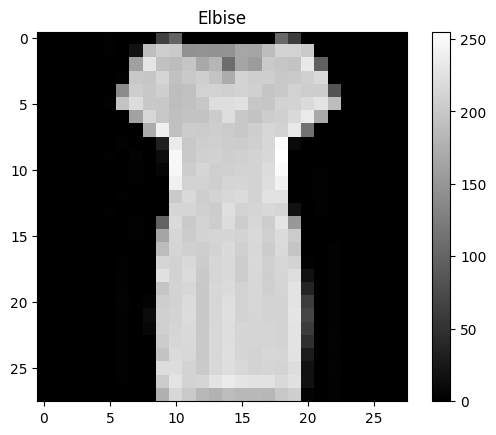

In [7]:
plt.imshow(x_train[20],cmap="gray")
plt.colorbar()
plt.title(sinif_adlari[y_train[20]])
plt.show()
#

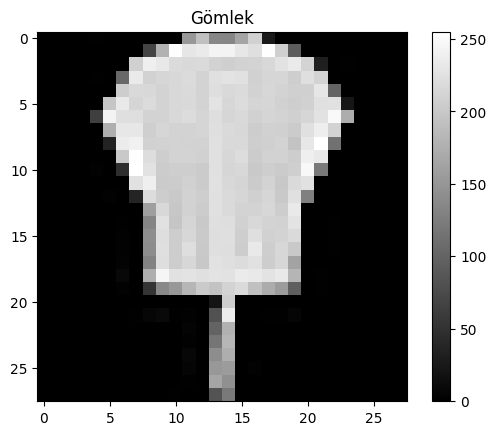

In [8]:
plt.imshow(x_train[56],cmap="gray")
plt.colorbar()
plt.title(sinif_adlari[y_train[56]])
plt.show()
#

In [9]:
#Her sınıfta kaç resim var.

print("Eğitim verisinde her sınıfta kaç resim var?")
print(np.bincount(y_train)) # 0 dan 9 a kadar her sayının kaç kez geçtiğini sayar.
print("Test verisinde her sınıfta kaç resim var?")
print(np.bincount(y_test))
#
#

Eğitim verisinde her sınıfta kaç resim var?
[6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
Test verisinde her sınıfta kaç resim var?
[1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [10]:
# NORMALİZASYON - SCALE ETME
# teoride konuştuğumuz üzere 0 - 255 arasında değerler olduğu için her sayıyı 255 e bölersek 0 - 1 arasına gelmiş olur. Normalize etmiş oluruz.

x_train = x_train / 255.0
x_test = x_test / 255.0

print("En küçük değer:", x_train.min())
print("En büyük değer:", x_train.max())


En küçük değer: 0.0
En büyük değer: 1.0


In [13]:
# MODELİ KURMA - SİNİR AĞI (DENSE)
keras.utils.set_random_seed(42)

dense_model = keras.Sequential([
    keras.Input(shape=(28,28)), # datamın modele her seferinde 28*28 lik bir resim geleceğini söylüyorum.
    layers.Flatten(), #teori notunda konuştuğumuz gibi datayı ağa 28*28 değil tekbir 784 sayılık tek bir satır olarak veriyor.
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax") # çoklu sınıflandırma yaptımız için softmax kullandık. 2 li olsaydı. sigmoid olaurdu.
])

dense_model.summary()




Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#100.480 sayısı = 784 * 128 + 128 = 100.480
#1290 sayısı = 128 * 10 + 10 = 1290

# neden 128 nöronla başladık. net bir kuralı yok. 64 veya 256 da denenebilirdi.

In [16]:
#MODELİ DERLEYECEĞİZ. Yani nasıl öğreneceğiniz söylüyoruz.

dense_model.compile(
    optimizer="adam", # learning rate, varsayılan değer olsun.
    loss="sparse_categorical_crossentropy", # loss fonksiyonu. Çoklu sınıflandırma için kayıp fonksiyonu. Model doğru sınıfa verdiği olasılık düştükçe daha çok ceza alır.
    metrics=["accuracy"] # Doğru tahmin oranını raporlar.
)

In [18]:
#MODELİ EĞİT(FIT)

dense_gecmis = dense_model.fit(x_train, y_train,
                               epochs=10,
                               batch_size=32,
                               validation_split=0.2 # eğitim datasının içinden %20 sini doğrulama için ayıracak.
                               )
#

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9176 - loss: 0.2255 - val_accuracy: 0.8844 - val_loss: 0.3453
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9194 - loss: 0.2183 - val_accuracy: 0.8851 - val_loss: 0.3617
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9226 - loss: 0.2100 - val_accuracy: 0.8862 - val_loss: 0.3531
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9257 - loss: 0.2017 - val_accuracy: 0.8877 - val_loss: 0.3611
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9271 - loss: 0.1962 - val_accuracy: 0.8869 - val_loss: 0.3489
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9313 - loss: 0.1894 - val_accuracy: 0.8852 - val_loss: 0.3752
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9326 - loss: 0.1845 - val_accuracy: 0.8866 - val_loss: 0.3672
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9352 - loss: 0.1773 -

60.000 datanın %20 si doğrulamaya ayırılırsa 48.000 data eğitim için 12.000 resim de doğrulama için ayrılmış olur. ( validation_split=0.2). Model 48.000 data ile eğitilir. 48.000 / 32(batch size) ile güncelenirse = 1500 adım sürer. toplam 10 epoch da süreceği için 15.000 ağırlık güncellemesi yapar.

In [20]:
# TEST VERİSİNİ DEĞERŞLENDİRME

dense_kayip, dense_doğruluk = dense_model.evaluate(x_test, y_test)

print("Test Kaybı:", dense_kayip)
print("Test Doğruluğu:", dense_doğruluk)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8744 - loss: 0.4273
Test Kaybı: 0.4272923469543457
Test Doğruluğu: 0.8744000196456909


In [24]:
olasiliklar = dense_model.predict(x_test)
print("Tahmin Tablosu:", olasiliklar.shape)
print(np.round(olasiliklar[0],3))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Tahmin Tablosu: (10000, 10)
[0.    0.    0.    0.    0.    0.    0.    0.001 0.    0.999]


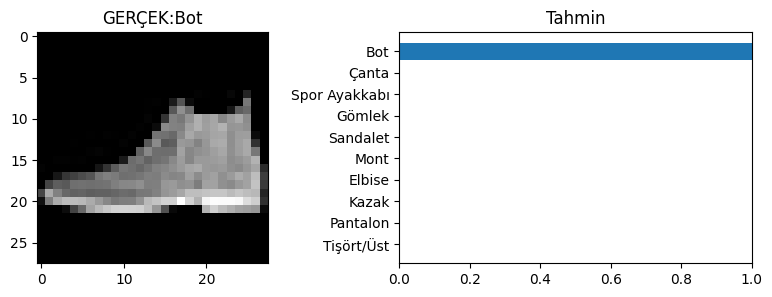

In [30]:
#Olasılığı Görselleştirme

plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.imshow(x_test[0],cmap="gray")
plt.title("GERÇEK:"+ sinif_adlari[np.argmax(olasiliklar[0])])
plt.subplot(1,2,2)
plt.barh(sinif_adlari, olasiliklar[0])
plt.title("Tahmin")
plt.xlim(0,1)

plt.show()

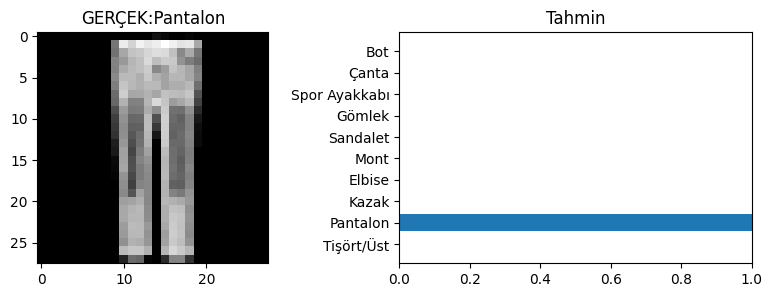

In [33]:
plt.figure(figsize=(10,3))
plt.subplot(1,2,1)
plt.imshow(x_test[15],cmap="gray")
plt.title("GERÇEK:"+ sinif_adlari[np.argmax(olasiliklar[15])])
plt.subplot(1,2,2)
plt.barh(sinif_adlari, olasiliklar[15])
plt.title("Tahmin")
plt.xlim(0,1)

plt.show()

In [35]:
print(classification_report(y_test, np.argmax(olasiliklar, axis=1)))
#

              precision    recall  f1-score   support

           0       0.86      0.76      0.81      1000
           1       0.98      0.97      0.98      1000
           2       0.83      0.73      0.78      1000
           3       0.91      0.87      0.89      1000
           4       0.75      0.86      0.80      1000
           5       0.97      0.96      0.97      1000
           6       0.66      0.73      0.69      1000
           7       0.91      0.97      0.94      1000
           8       0.93      0.97      0.95      1000
           9       0.97      0.93      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.88      0.87      0.87     10000
weighted avg       0.88      0.87      0.87     10000

